---
---

<h1><center><ins>Exercise Sheet 7</ins></center></h1>
<h2><center>Numerical Methods <br><br>

---
---

In [1]:
import numpy as np
import matplotlib.pyplot as plt

""" 
Set some defaults, most of all: LARGE fonts
"""
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'xx-large',
          'figure.figsize': (12, 7),
         'axes.labelsize': 'xx-large',
         'axes.titlesize':'xx-large',
         'xtick.labelsize':'xx-large',
         'ytick.labelsize':'xx-large'}
pylab.rcParams.update(params)

## Exercise 1 - Backward Euler:

Consider the following first-order ODE:

$$ \frac{d y}{dt} = - 3 y \ , $$

**(A)** Solve this ODE with **your own forward Euler** implementation for $0\leq t\leq20$. Use the following step sizes: $\Delta t = 0.1, 0.25, 0.5, 0.75$, and plot the numerical solution for all four step sizes in four different figures. Also compare it with the exact analytical solution in the corresponding plot. Discuss your findings.

**(B)** Now implement **your own backward Euler** implementation and repeat all the steps from **(A)**. What do you notice?


Backward Euler for exponential like function $\frac{dy}{dt} = a y$:

 $y_{n+1} = y_n + \Delta t \, (\frac{dy}{dt})$, hence $y_{n+1} = y_n + a \, \Delta t \, y_{n+1}$, hence $y_{n+1} = \frac{y_n}{1 - a \, \Delta t}$.

In [2]:
def forw_euler(df, t0, tend, y0, dt):
    """
    df:     callable function, the derivative, can be a vector
    t0:     start time
    tend:   end time
    y0:     initial condition, can be a vector, must have same dimens as df
    dt:     time increment
    Forward Euler integration of a single or coupled system of ODE's
    RETURNS:
    ts:     an array of time instances, where the ODE was calculated
    ys:     an array of objects, which can be scalar or arrays, depending on the dimens of df and y0
            containing the results
    """
    ts = [t0]
    ys = [np.array(y0, dtype=float)]
    t = t0
    y = np.array(y0, dtype=float)

    while t < tend:
        h = min(dt, tend - t)       # if the last interval does not contain a full dt
        y = y + h * df(t, y)        # new y equals old y + dt * slope at old t
        t += h
        ys.append(y.copy())         # avoid side effects, remember that y can be a vector
        ts.append(t)
    return np.array(ts), np.array(ys)

def backw_euler_decay(a, t0, tend, y0, dt):
    """
    a:      exponent in exponential
    t0:     start time
    tend:   end time
    y0:     initial condition
    dt:     time increment
    Backward Euler integration for special case of exponential
    RETURNS:
    ts:     an array of time instances, where the ODE was calculated
    ys:     an array of y values
    """
    ts = [t0]
    ys = [y0]
    t = t0
    y = y0

    while t < tend:
        h = min(dt, tend - t)       # if the last interval does not contain a full dt
        y = y / ( 1 - a*h)
        t += h
        ys.append(y)       
        ts.append(t)
    return np.array(ts), np.array(ys)


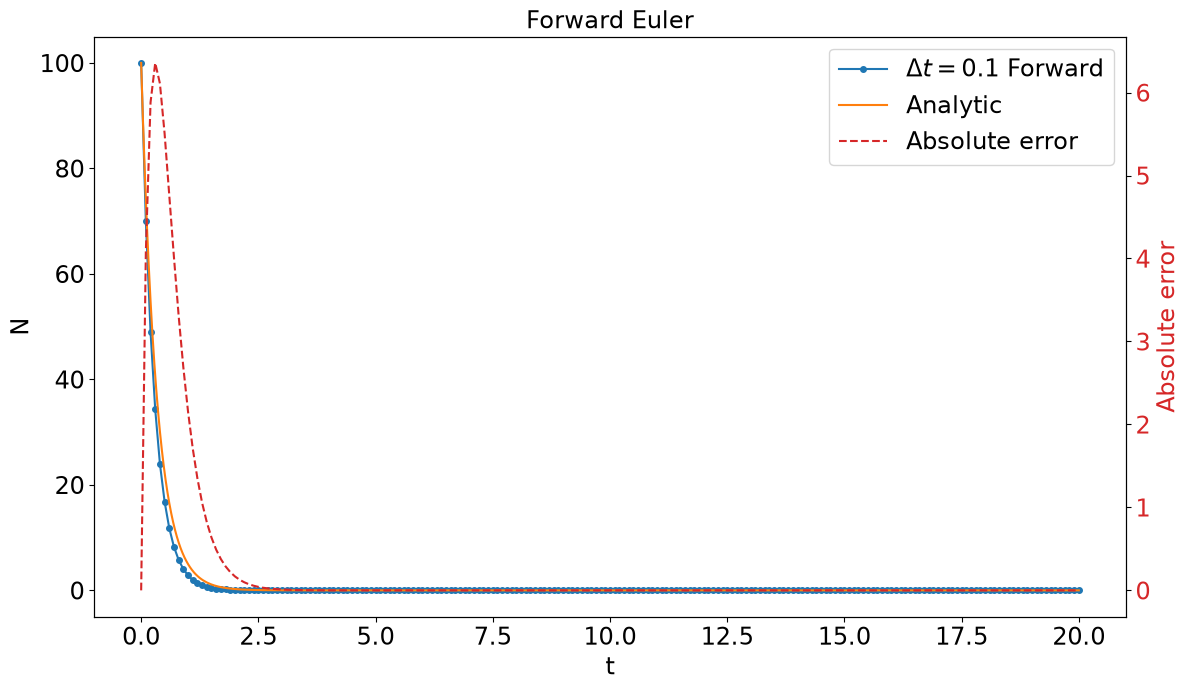

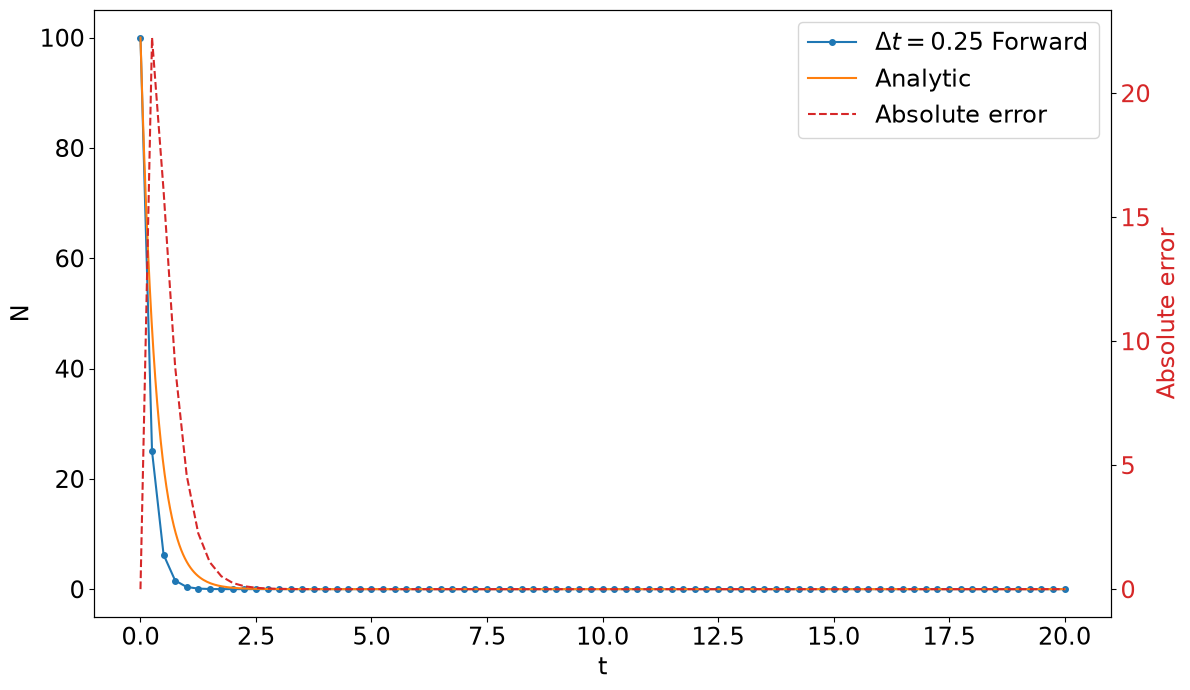

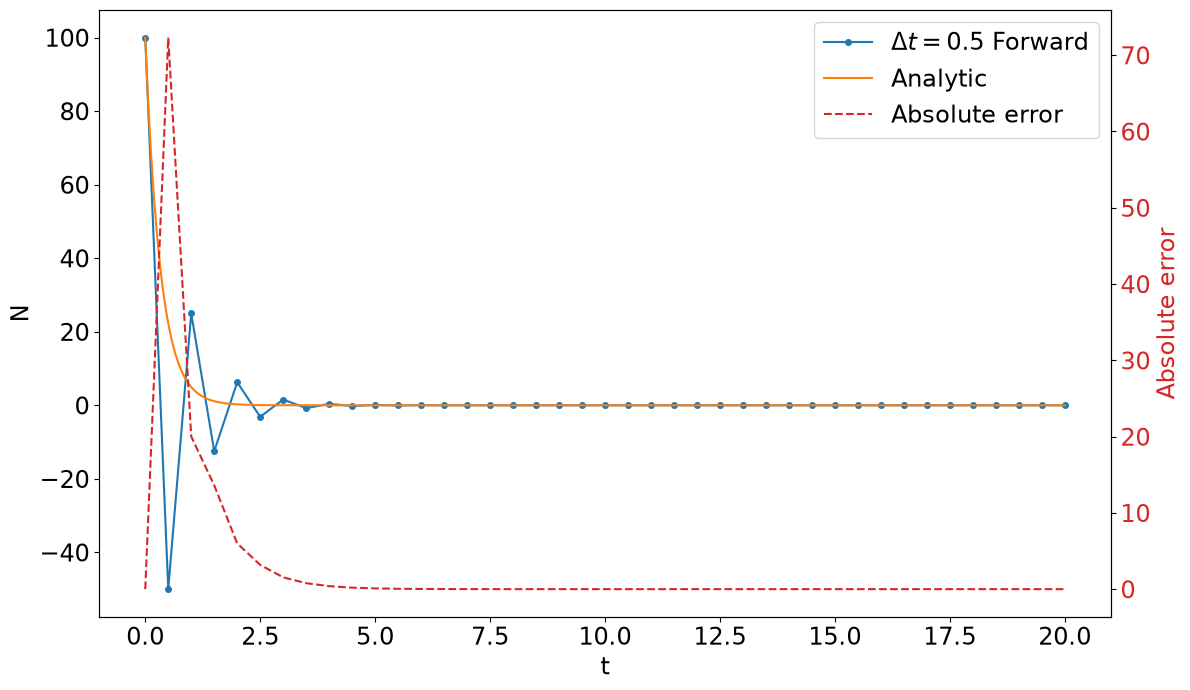

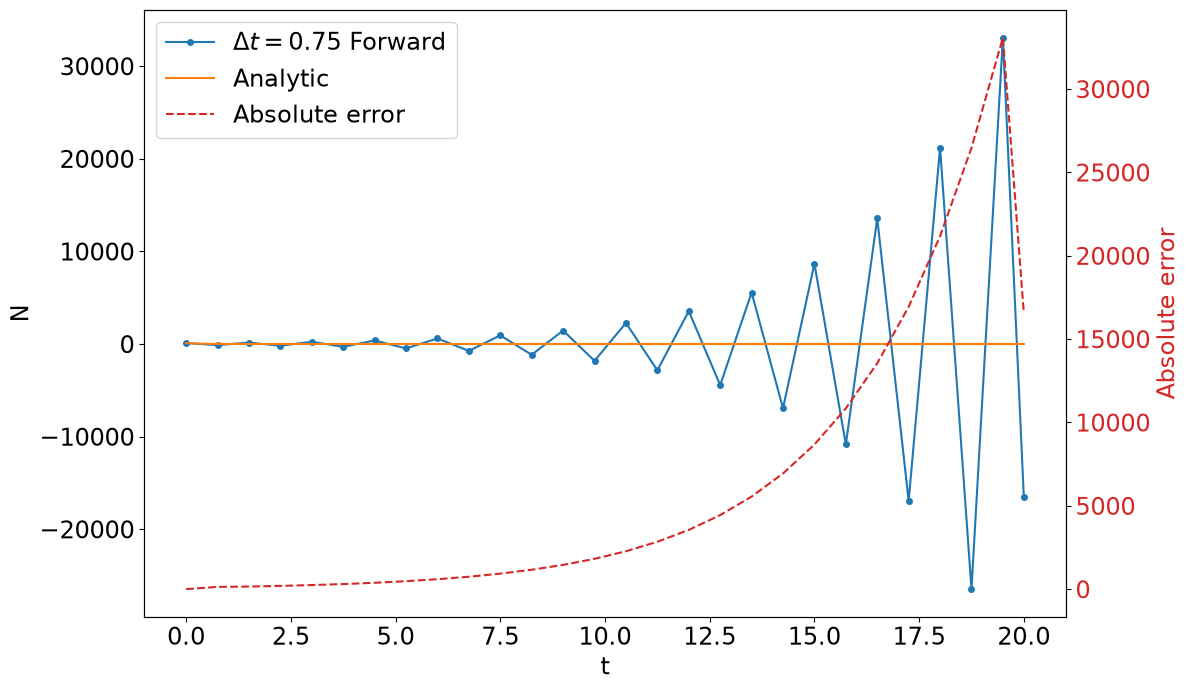

In [3]:
#(A)

def decay(t, y):
    return -3 * y

def decay_analytic(t, lam, y0):
    return y0 * np.exp(-lam * t)

N0 = 100
start_time = 0
end_time = 20

ts = np.linspace(start_time, end_time, 500)
Ns = decay_analytic(ts, 3, N0)

dts = [0.1, 0.25, 0.5, 0.75]
for dt in dts:
    t, y = forw_euler(decay, start_time, end_time, N0, dt)

    error = np.abs(y - decay_analytic(t, 3, N0))

    fig, ax1 = plt.subplots()
    ax2 = ax1.twinx()

    # Numerische und analytische Lösung
    ax1.plot(t, y, '-o', markersize=4,
             label=fr'$\Delta t = {dt}$ Forward')
    ax1.plot(ts, Ns, label='Analytic')

    # Absolute Abweichung
    ax2.plot(t, error, '--', color='tab:red',
             label='Absolute error')

    ax1.set_xlabel('t')
    ax1.set_ylabel('N')
    ax2.set_ylabel('Absolute error', color='tab:red')
    ax2.tick_params(axis='y', labelcolor='tab:red')

    # Gemeinsame Legende
    lines = ax1.get_lines() + ax2.get_lines()
    ax1.legend(lines, [line.get_label() for line in lines])

    if dt == 0.1:
        ax1.set_title('Forward Euler')

    fig.tight_layout()
    plt.show()

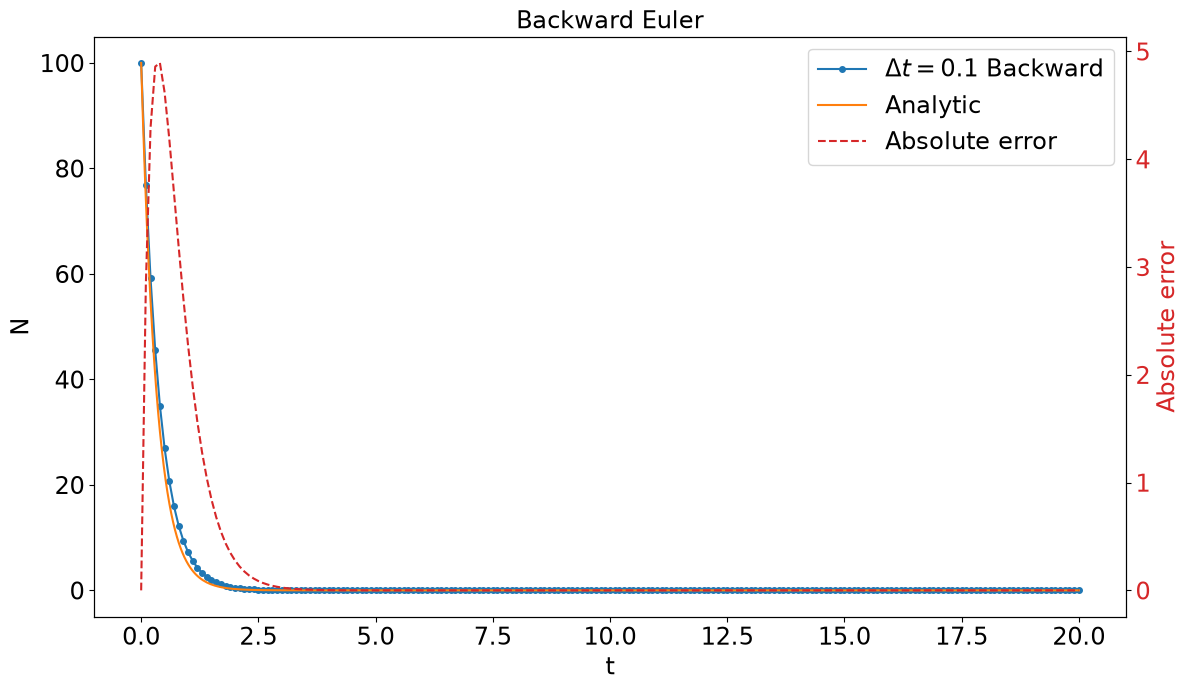

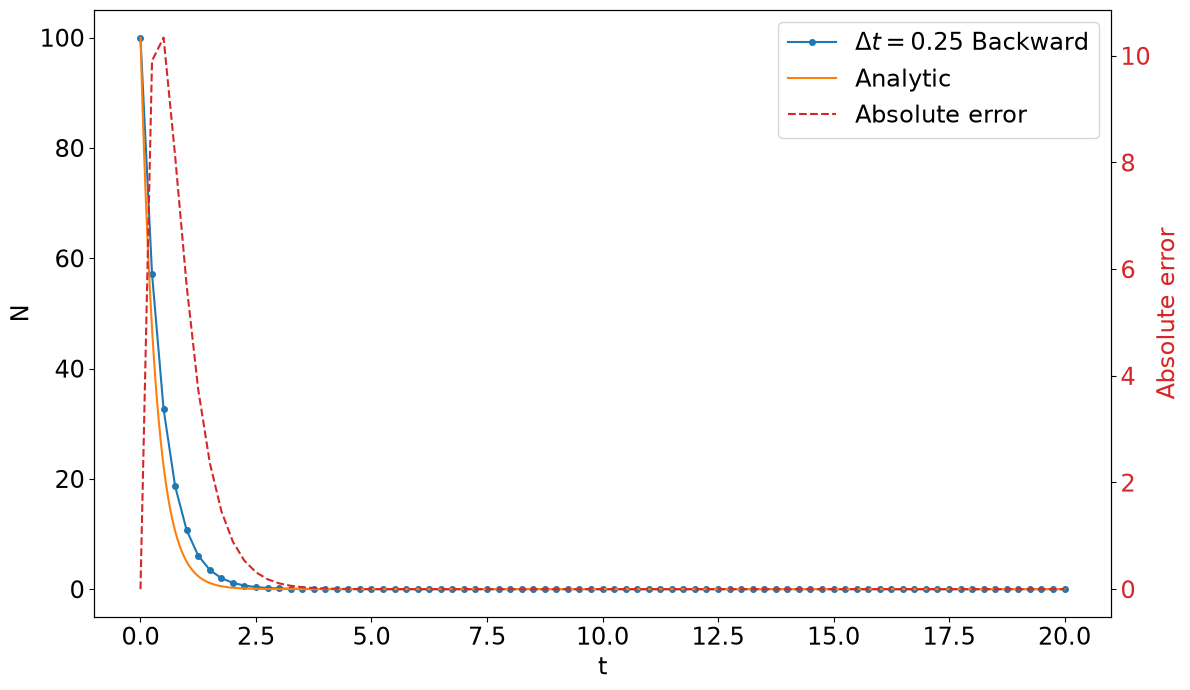

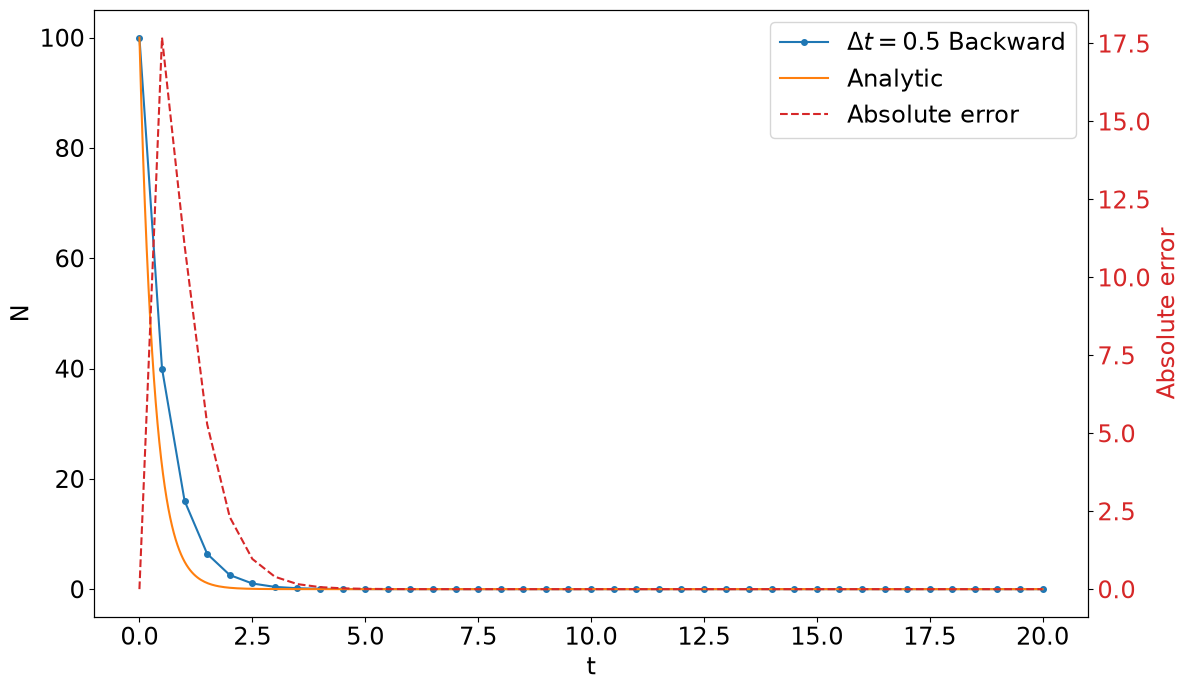

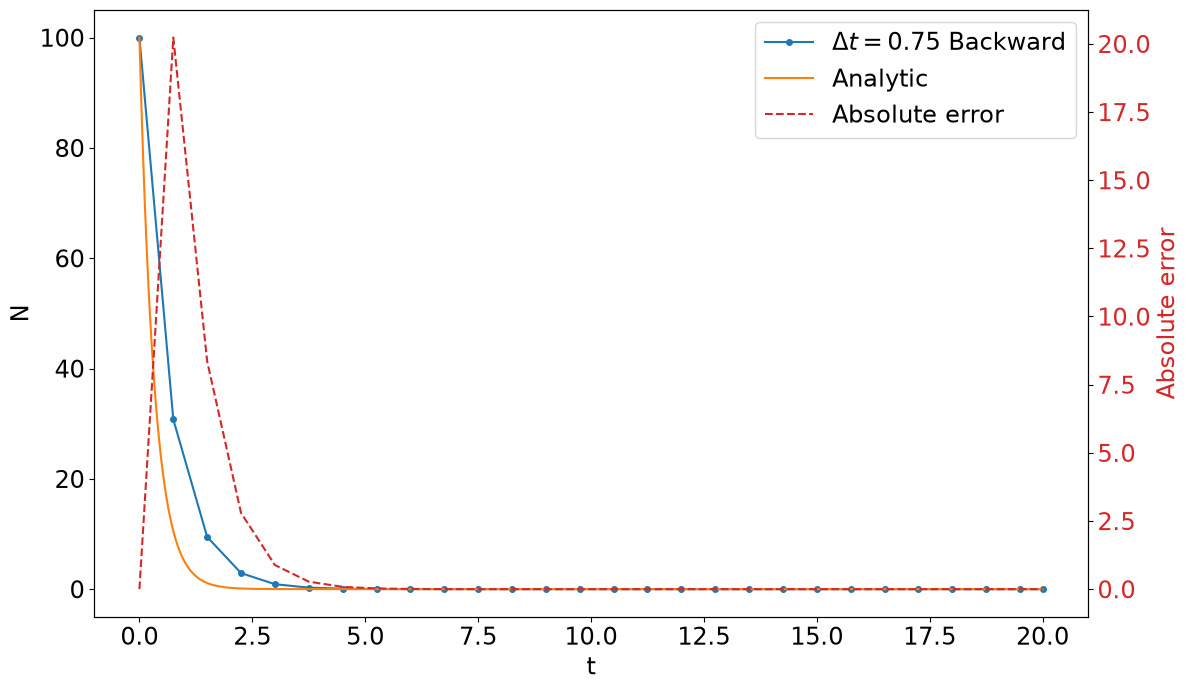

In [4]:
#(B)
dts = [0.1, 0.25, 0.5, 0.75]
ts = np.linspace(start_time, end_time, 500)
Ns = decay_analytic(ts, 3, N0)
for dt in dts:
    t_b, y_b = backw_euler_decay(-3, start_time, end_time, N0, dt)
    error = np.abs(y_b - decay_analytic(t_b, 3, N0))

    fig, ax1 = plt.subplots()
    ax2 = ax1.twinx()

    # Numerische und analytische Lösung
    ax1.plot(t_b, y_b, '-o', markersize=4,
             label=fr'$\Delta t = {dt}$ Backward')
    ax1.plot(ts, Ns, label='Analytic')

    # Absolute Abweichung
    ax2.plot(t_b, error, '--', color='tab:red',
             label='Absolute error')

    ax1.set_xlabel('t')
    ax1.set_ylabel('N')
    ax2.set_ylabel('Absolute error', color='tab:red')
    ax2.tick_params(axis='y', labelcolor='tab:red')

    # Gemeinsame Legende
    lines = ax1.get_lines() + ax2.get_lines()
    ax1.legend(lines, [line.get_label() for line in lines])

    if dt == 0.1:
        ax1.set_title('Backward Euler')

    fig.tight_layout()
    plt.show()

For Forward Euler $\Delta t = 0.1$ the solution is ok, for 0.25 still useful, at 0.5 it oscillates, and at higher values the solution diverges and becomes totally useless.

On the other hand, Backward Euler gives useful results even with $\Delta t = 0.75$

**(C)** What complication arises in the implementation of the backward Euler, if we replace the right hand side of the ODE with $ (1-\frac{y}{3})y $? What kind of numerical methods already known from the lecture can you use to solve the arising equation? Please implement them to solve this ODE with the backward Euler and compare your solution with analytic one by plotting them in a figure.

The complications are that in general we will get an equation for $y_{n+1}$ which cannot be solved analytically. In this particular case it would be possible to solve it, but in the general case not. So we will address here the general case, and use Newton-Raphson for the root finding. As start value we can use the forward Euler value.

$\frac{dy}{dt} = (1 - \frac{y}{3}) \, y$

 $y_{n+1} = y_n + \Delta t \, (\frac{dy}{dt})$

 $z := y_{n+1}, \, h := \Delta t$
 
 $z = y_n + h (1 - \frac{z}{3}) \, z$
 
 $G(z) = z - y_n - h \, (z - \frac{z^2}{3})$

 $G'(z) = 1 - h + \frac{2h}{3}z $

In [5]:
def NewtRaph(f, df, x, eps, maxiter=1000):
    """Newton-Raphson method of root finding """
    if not callable(f):
        raise ValueError("First argument is not a function")
    if not callable(df):
        raise ValueError("Second argument is not a function")

    yn = f(x)
    iter = 0
    if (abs(yn) < eps):
        return x, yn, iter
    while iter < maxiter:
        xn = x - yn / df(x)
        yn = f(xn)
        iter += 1
        if (abs(yn) <= eps) or abs(x - xn) < eps:
            return xn, yn, iter
        x = xn
    raise ValueError("too may iterations")

def backw_euler_Newton(f, G, dG, t0, tend, y0, dt):
    """
    f:      callable: the RHS of the ODE
    G:      callable: the RHS put into the backward Euler formula
    dG:     callable: dG/dz
    t0:     start time
    tend:   end time
    y0:     initial condition
    dt:     time increment
    Backward Euler integration
    RETURNS:
    ts:     an array of time instances, where the ODE was calculated
    ys:     an array of objects, which can be scalar or arrays, depending on the dimens of df and y0
            containing the results
    """
    ts = [t0]
    ys = [y0]
    t = t0
    y = y0

    while t < tend:
        h = min(dt, tend - t)       # if the last interval does not contain a full dt
        g = lambda z: G(z, y, h)
        dg = lambda z: dG(z, h)
        y_trial = y + h * f(y)    # forward Euler as start point
        y, _, _ = NewtRaph(g, dg, y_trial, 1e-12)
        t += h
        ys.append(y)       
        ts.append(t)
    return np.array(ts), np.array(ys)


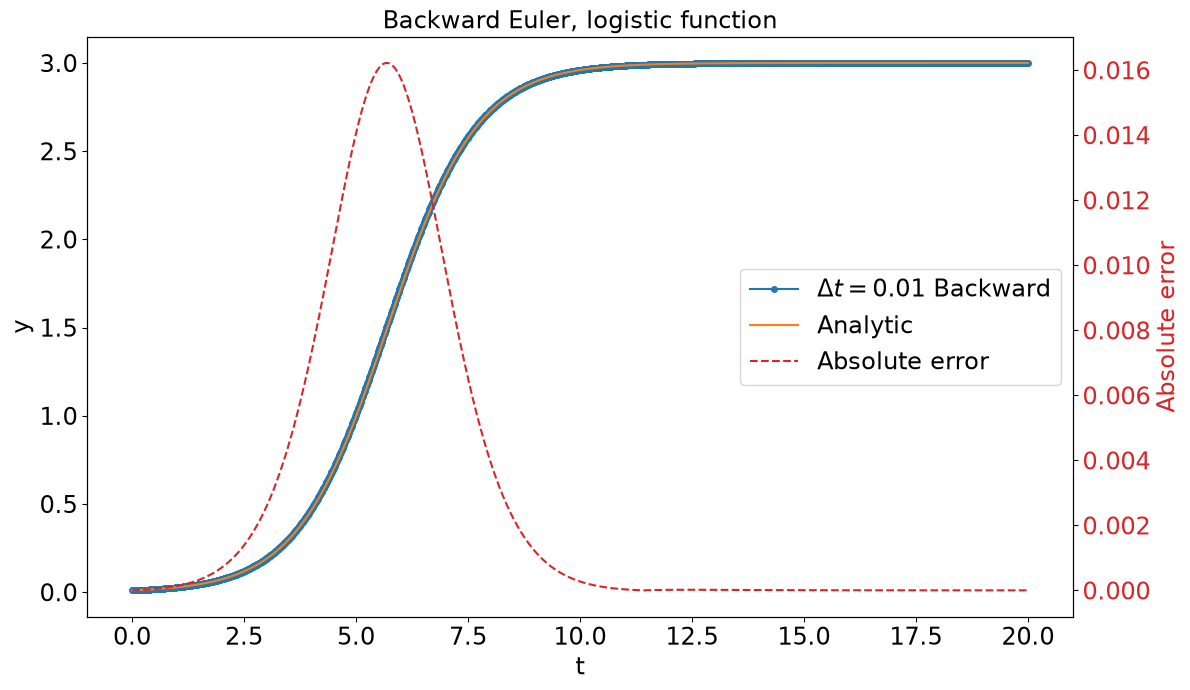

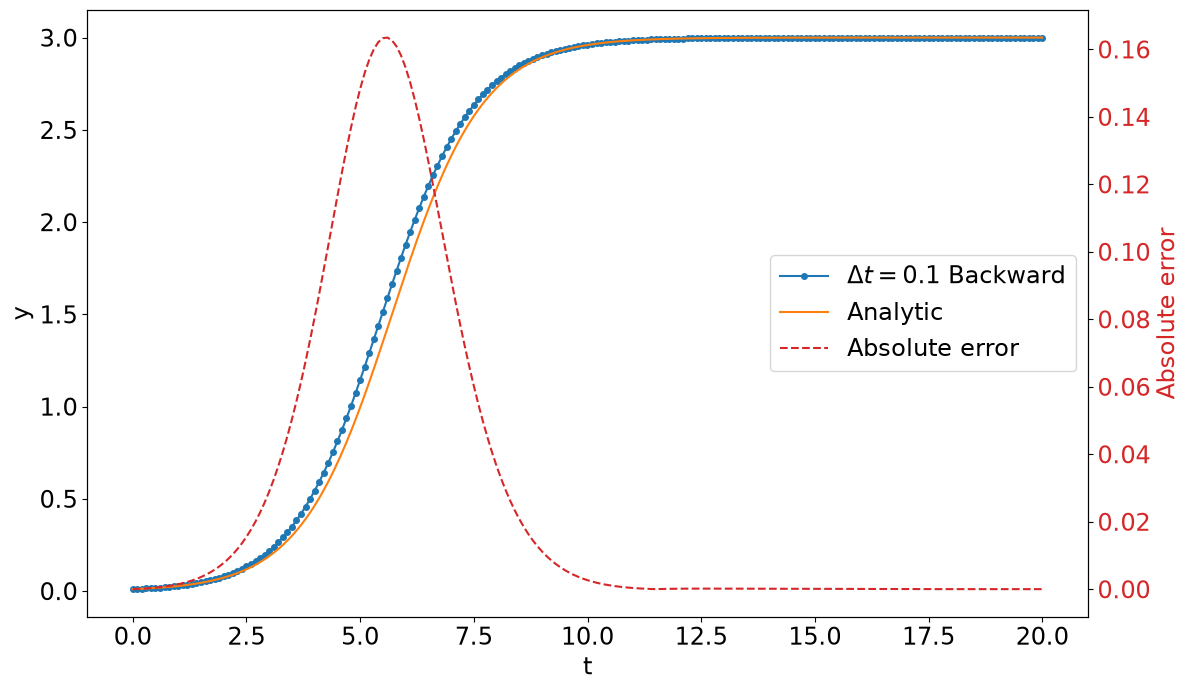

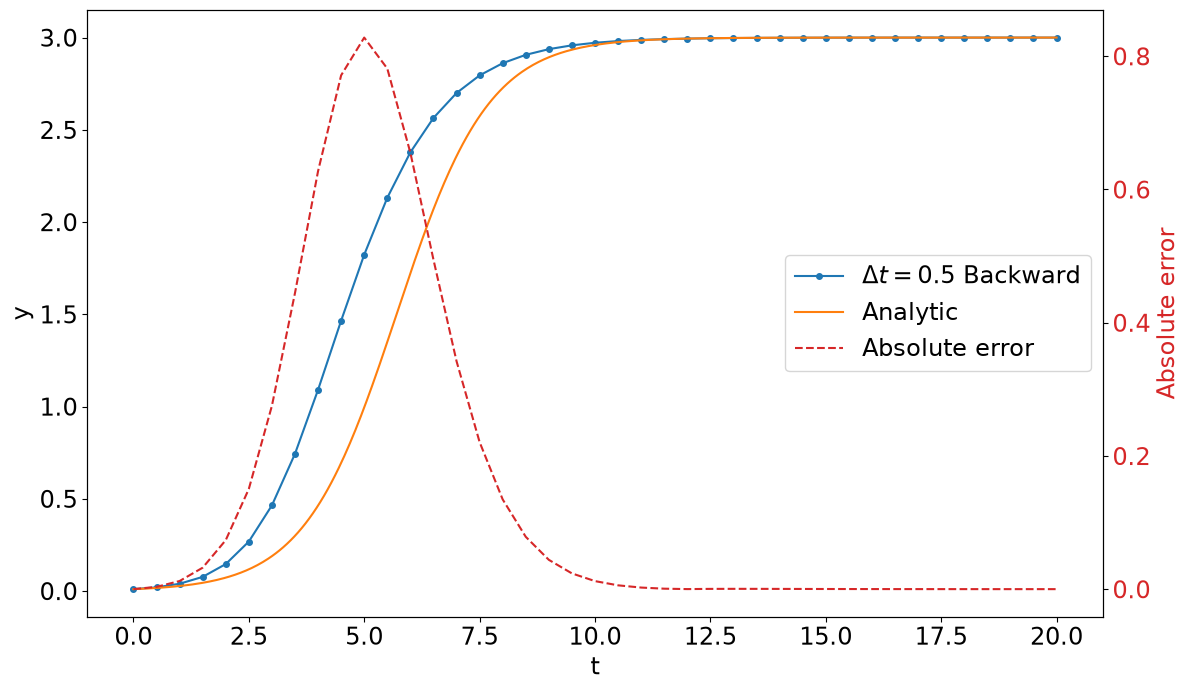

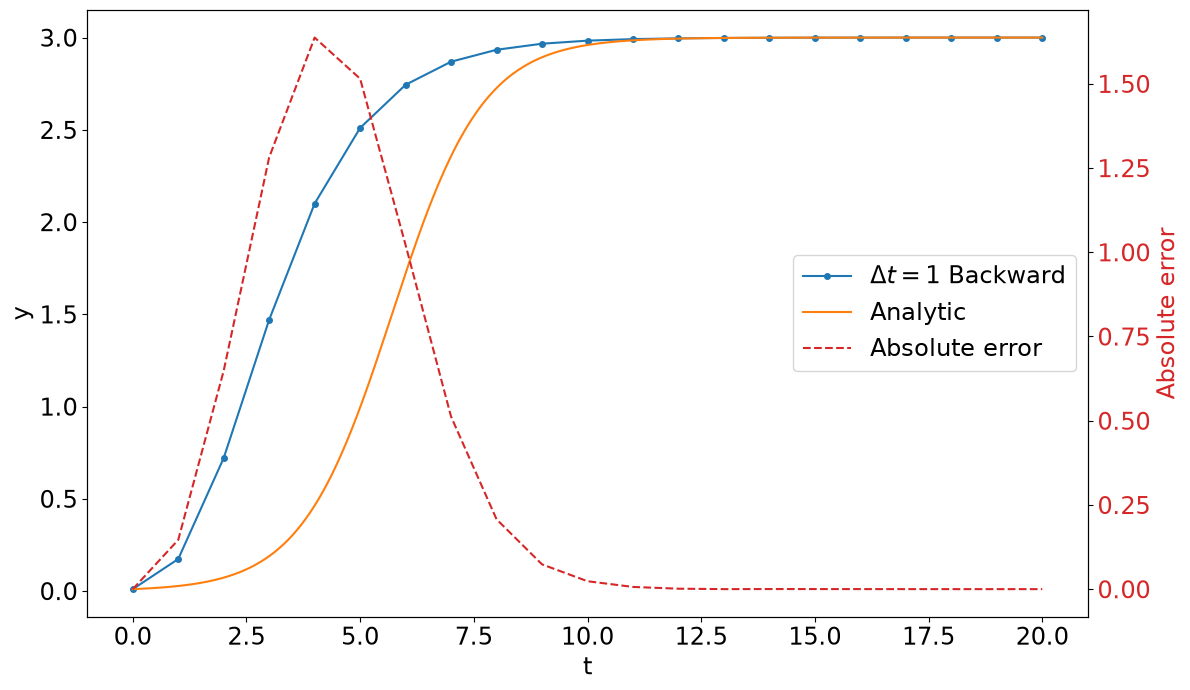

In [6]:
def logistic_analytic(t, t0, y0):
    return 3 / (1 + (3/y0 -1) * np.exp(-(t - t0)))

def RHS(y):
    return (1 - y/3) * y

def G(z, yn, h):
    return z - yn - h * RHS(z)

def dG(z, h):
    return 1 - h + 2 * h * z / 3

y0 = 0.01
start_time = 0
end_time = 20

ts = np.linspace(start_time, end_time, 500)
Ns = logistic_analytic(ts, start_time, y0)

dts = [0.01, 0.1, 0.5, 1]

for dt in dts:
    t, y = backw_euler_Newton(RHS, G, dG, start_time, end_time, y0, dt)
    error = np.abs(y - logistic_analytic(t, start_time, y0))

    fig, ax1 = plt.subplots()
    ax2 = ax1.twinx()

    # Numerische und analytische Lösung
    ax1.plot(t, y, '-o', markersize=4,
             label=fr'$\Delta t = {dt}$ Backward')
    ax1.plot(ts, Ns, label='Analytic')

    # Absolute Abweichung
    ax2.plot(t, error, '--', color='tab:red',
             label='Absolute error')

    ax1.set_xlabel('t')
    ax1.set_ylabel('y')
    ax2.set_ylabel('Absolute error', color='tab:red')
    ax2.tick_params(axis='y', labelcolor='tab:red')

    # Gemeinsame Legende
    lines = ax1.get_lines() + ax2.get_lines()
    ax1.legend(lines, [line.get_label() for line in lines], loc='center right')

    if dt == dts[0]:
        ax1.set_title('Backward Euler, logistic function')

    fig.tight_layout()
    plt.show()

## Exercise 2 - Backward Euler Part 2:

Consider now the following second-order ODE:

$$ y^{\prime\prime} + 6 y^{\prime} + 5y = 10, $$

with initial conditions of $y(0) = 0$ and $y^{\prime}(0) = 5.$

**(A)** Solve this ODE with **your own backward Euler** implementation for $0\leq t\leq5$. What is the linear system of equation that you have to solve? (write it down in matrix notation). Within **your own backward Euler** implementation you are free to solve this system of equation using either numerical methods (e.g. np.linalg.solve) or invert the matrix by hand. Use a step size of 0.1 and 0.5. Plot the absolute error of the numerical solutions for both steps sizes compared to the exact solution. The exact solution is 

$$ y(t) = -\frac{3}{4}e^{-5t} -\frac{5}{4}e^{-t} + 2. $$


**(B)** Repeat **(A)** using **forward Euler**. What do you notice?

I will solve the example for the ODE y" + ay' + by + c = 0

y" = -ay' -by -c

we define:

y' = v, v' = -av -by -c

$y_{n+1} = y_n + hy'$

$y_{n+1} = y_n + hv_{n+1}$

$y_{n+1} - hv_{n+1} = y_n$   (eq. 1)

$v_{n+1} = v_n + h(-av_{n+1} -by_{n+1} -c)$



$bhy_{n+1} + (1 + ah)v_{n+1} = v_n - ch$

$1\,\, y_{n+1} - hv_{n+1} = y_n$  (= eq. 1)

$\begin{pmatrix} 1 & -h \\ bh & 1 + ah \end{pmatrix} \begin{pmatrix} y_{n+1} \\ v_{n+1} \end{pmatrix} = \begin{pmatrix} y_n \\ v_n - ch \end{pmatrix}$



In [13]:
from scipy.linalg import solve

def backw_euler_2nd_order_ODE(a, b, c, t0, tend, y0, dy0, dt):
    """
    a,b,c:  coefficients of the ODE y" + ay' + by + c = 0
    t0:     start time
    tend:   end time
    y0:     initial condition y
    dy0:    initial condition y'
    dt:     time increment
    Backward Euler integration for special case of y" + ay' + by + c = 0
    RETURNS:
    ts:     an array of time instances, where the ODE was calculated
    ys:     an array of y values
    """
    ts = [t0]
    ys = [y0]
    t = t0
    y = y0
    v = dy0

    while t < tend:
        h = min(dt, tend - t)       # if the last interval does not contain a full dt
        # now set up the matrix
        A = np.array([[1, -h], [b*h, 1 + a*h]])
        R = np.array([y, v - c*h])
        y, v = solve(A, R)   # and solve
        t += h
        ys.append(y)       
        ts.append(t)
    return np.array(ts), np.array(ys)

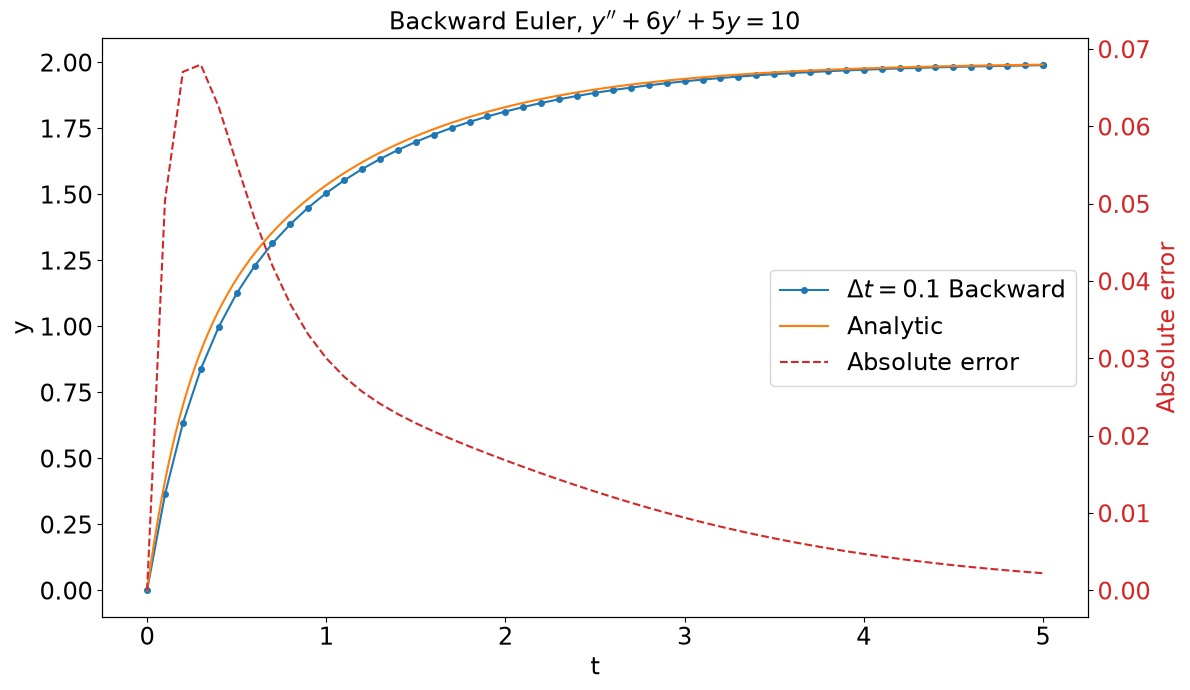

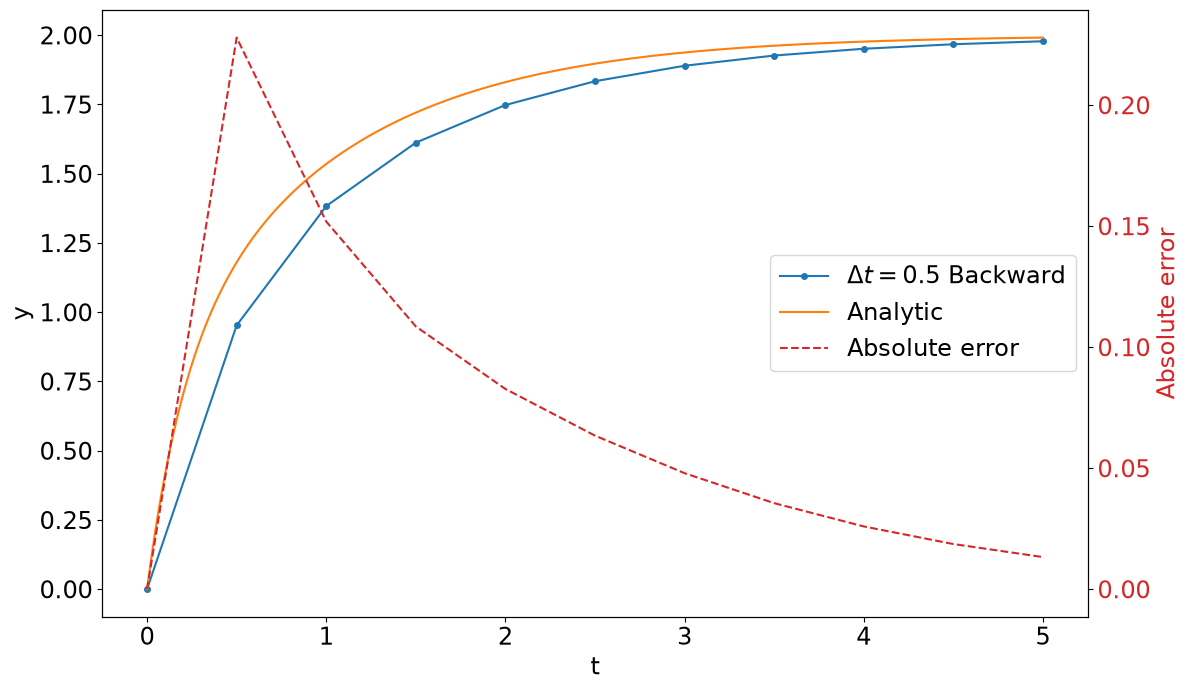

In [14]:
def analytic(t):
    return 2 - 5/4*np.exp(-t) - 3/4*np.exp(-5*t)

start_time = 0
end_time = 5

ts = np.linspace(start_time, end_time, 500)
Ns = analytic(ts)

dts = [0.1, 0.5]

for dt in dts:
    t, y = backw_euler_2nd_order_ODE(6, 5, -10, start_time, end_time, 0, 5, dt)
    error = np.abs(y - analytic(t))

    fig, ax1 = plt.subplots()
    ax2 = ax1.twinx()

    # Numerische und analytische Lösung
    ax1.plot(t, y, '-o', markersize=4,
             label=fr'$\Delta t = {dt}$ Backward')
    ax1.plot(ts, Ns, label='Analytic')

    # Absolute Abweichung
    ax2.plot(t, error, '--', color='tab:red',
             label='Absolute error')

    ax1.set_xlabel('t')
    ax1.set_ylabel('y')
    ax2.set_ylabel('Absolute error', color='tab:red')
    ax2.tick_params(axis='y', labelcolor='tab:red')

    # Gemeinsame Legende
    lines = ax1.get_lines() + ax2.get_lines()
    ax1.legend(lines, [line.get_label() for line in lines], loc='center right')

    if dt == dts[0]:
        ax1.set_title(r'Backward Euler, $y^{\prime\prime} + 6 y^{\prime} + 5y = 10$')

    fig.tight_layout()
    plt.show()

$$ y^{\prime\prime} = - 6 y^{\prime} - 5y + 10 $$
$$u = y^{\prime}, v = y$$
$$u^{\prime} = y^{\prime\prime} = -6 u - 5 v + 10$$
$$v^{\prime} = u$$




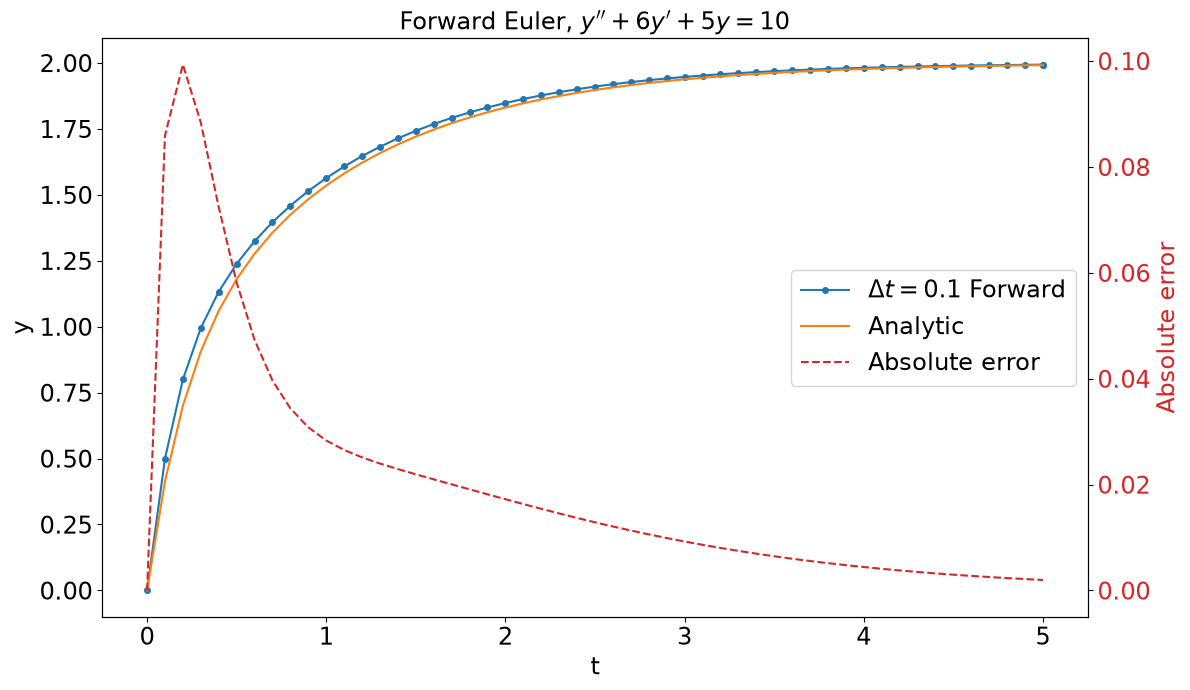

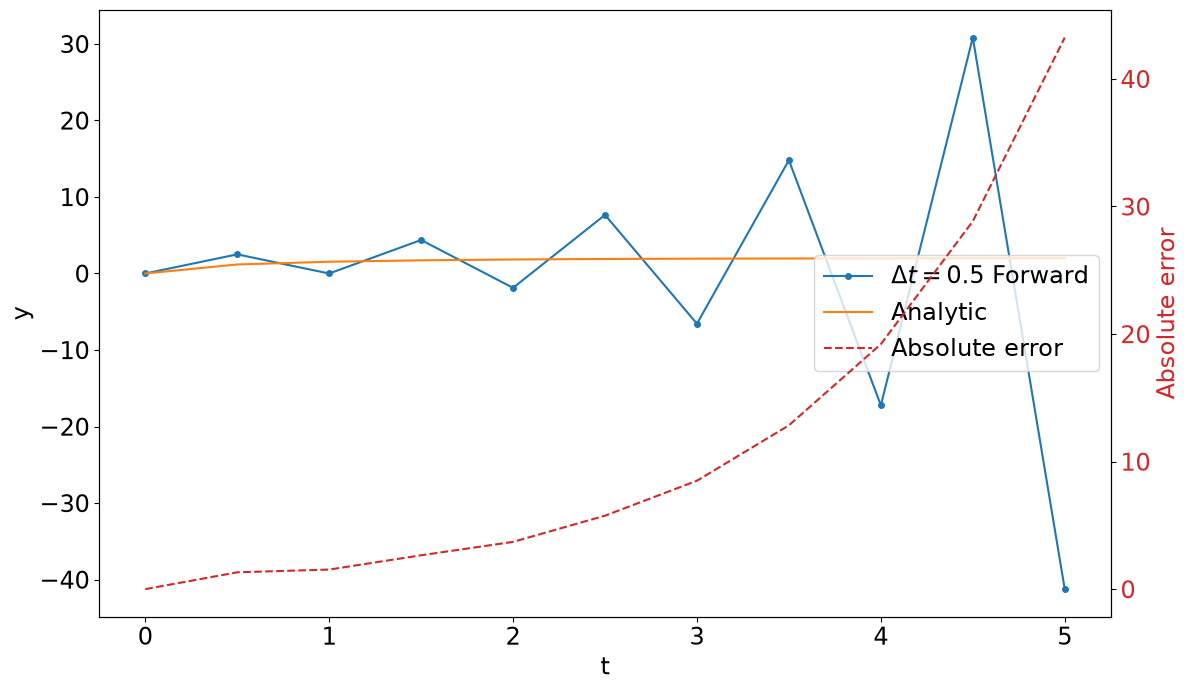

In [15]:
# 2.B
def analytic(t):
    return 2 - 5/4*np.exp(-t) - 3/4*np.exp(-5*t)

def my_ODE(x, y):
    u, v = y
    du = -6*u - 5*v + 10
    dv = u
    return np.array([du, dv])

start_time = 0
end_time = 5

dts = [0.1, 0.5]

for dt in dts:
    t, eul = forw_euler(my_ODE, start_time, end_time, (5, 0), dt)
    y = eul[:, 1]
    y_ana = analytic(t)
    error = np.abs(y - y_ana)

    fig, ax1 = plt.subplots()
    ax2 = ax1.twinx()

    # Numerische und analytische Lösung
    ax1.plot(t, y, '-o', markersize=4,
             label=fr'$\Delta t = {dt}$ Forward')
    ax1.plot(t, y_ana, label='Analytic')

    # Absolute Abweichung
    ax2.plot(t, error, '--', color='tab:red',
             label='Absolute error')

    ax1.set_xlabel('t')
    ax1.set_ylabel('y')
    ax2.set_ylabel('Absolute error', color='tab:red')
    ax2.tick_params(axis='y', labelcolor='tab:red')

    # Gemeinsame Legende
    lines = ax1.get_lines() + ax2.get_lines()
    ax1.legend(lines, [line.get_label() for line in lines], loc='center right')

    if dt == dts[0]:
        ax1.set_title(r'Forward Euler, $y^{\prime\prime} + 6 y^{\prime} + 5y = 10$')

    fig.tight_layout()
    plt.show()

While the backward Euler still gave a useful solution for $\Delta t = 0.5$, the forward Euler becomes unstable at 0.5. The absolute errors at 0.1 are very similar, so the conclusion is, where they both converge, backward is almost no advantage, but the benefit of backward Euler is that it still converges, where forward Euler goes belly up.

## Exercise 3 - More Oscillators:

Consider again a system of a mass that is attached to a spring. We have seen (look at Exercise Sheet 6 Exercise Number 3) that the resuling ODE describing such a system is of the form

$$ \frac{d^2 x}{dt^2} = - \frac{k}{m} x \ , $$

where $m$ is the mass of your particle, $k$ is the spring constant, and $x$ is the displacement from the equilibrium position.

**(A)** Implement the Leapfrog integration in oder to solve this ODE. Follow the section "Algorithm" under https://en.wikipedia.org/wiki/Leapfrog_integration. Consider the same values for the constants and initial conditions from Exercise Sheet 6 and plot your result by comparing with the analytic solution. Is the accuracy the same as for the Kunge-Kutta method? Why is this integrator called leapfrog? Name one advantage of the leapfrog integration over other methods such as Kunge-Kutta.

Consider now the damped oscillator of the form:

$$ \frac{d^2 x}{dt^2} = - \frac{k}{m} x - \frac{D}{m} \frac{dx}{dt} \ , $$

where $D$ is an additional friction coefficient.

**(B)**
Solve this ODE with the Runge-Kutta method. Either use the build-in python function or your own implementation. Play around with different values for $D$ and compare it to the analytic solution (you may use : https://lemesurierb.people.charleston.edu/numerical-methods-and-analysis-python/main/ODE-IVP-4-system-higher-order-equations-python.html#equation-equation-damped-mass-spring to help you with the analytic solution). Consider all three possibilities of the system being (1) underdamped, (2) overdamped and (3) critically damped (What do these terms mean?). Make a plot for all three cases to show your numerical and analytic solution.

**(C)**
What problem arises if you were to solve the damped oscillator with the leapfrog algorithm? What could be a possible solution to that problem?

In [10]:
# 3.A
def leapfrog(f, t0, tend, x0, v0, dt, args=()):
    """
    f:      callable function, the acceleration at point x
    t0:     start time
    tend:   end time
    v0:     initial speed
    x0:     initial position
    dt:     time increment
    Leapfrog integration of an equation of form x" = A(x)
    RETURNS:
    ts:     an array of time instances, where the ODE was calculated
    xs:     an array of x positions
    vs:     an array of velocities
    """
    N = int(np.ceil((tend - t0) / dt))
    h = (tend - t0) / N
    ts = np.linspace(t0, tend, N + 1)
    xs = [np.array(x0, dtype=float)]
    vs = [np.array(v0, dtype=float)]
    x = np.array(x0, dtype=float)
    v = np.array(v0, dtype=float)
    for t in ts[1:]:
        a_old = f(x, *args)
        x = x + v*h + 0.5*a_old*h**2
        a_new = f(x, *args)
        v = v + 0.5*(a_old + a_new)*h

        xs.append(x.copy())
        vs.append(v.copy())

    return np.array(ts), np.array(xs), np.array(vs)

def RK4(df, t0, tend, y0, dt, args=()):
    """
    df:     callable function, the derivative, can be a vector
    t0:     start time
    tend:   end time
    y0:     initial condition, can be a vector, must have same dimens as df
    dt:     time increment
    Runge-Kutte 4th order (classical) integration of a single or coupled system of ODE's
    corresponds to this Butcher Tableau:
    0   |
    1/2 | 1/2
    1/2 | 0   1/2
    1   | 0    0   1
    ______________________
        | 1/6 1/3 1/3 1/6
        
    RETURNS:
    ts:     an array of time instances, where the ODE was calculated
    ys:     an array of objects, which can be scalar or arrays, depending on the dimens of df and y0
            containing the results
    """    
    ts = [t0]
    ys = [np.array(y0, dtype=float)]
    t = t0
    y = np.array(y0, dtype=float) 
    while t < tend:
        h = min(dt, tend - t)
        k1 = df(t, y, *args)
        k2 = df(t + h/2, y + h/2 * k1, *args)
        k3 = df(t + h/2, y + h/2 * k2, *args)
        k4 = df(t + h, y + h * k3, *args)
        y = y + h / 6 * (k1 + 2*k2 + 2*k3 + k4)
        t += h
        ys.append(y.copy())
        ts.append(t)
    return np.array(ts), np.array(ys)  

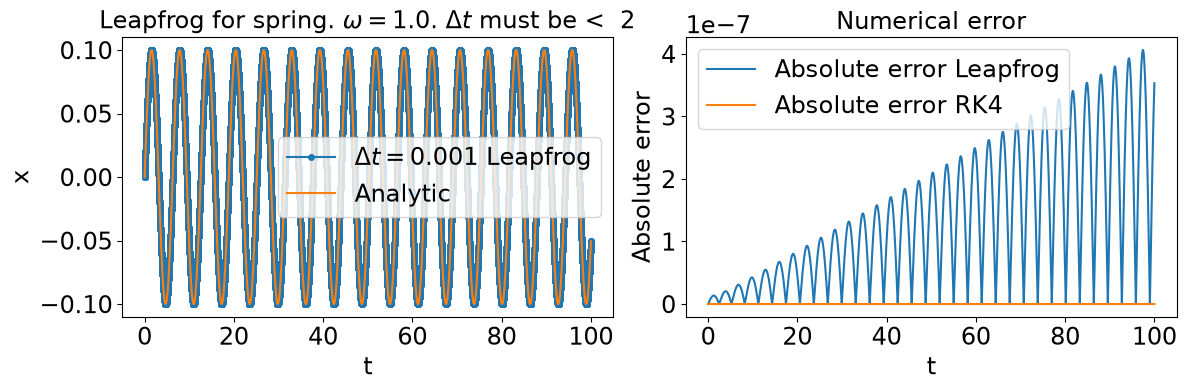

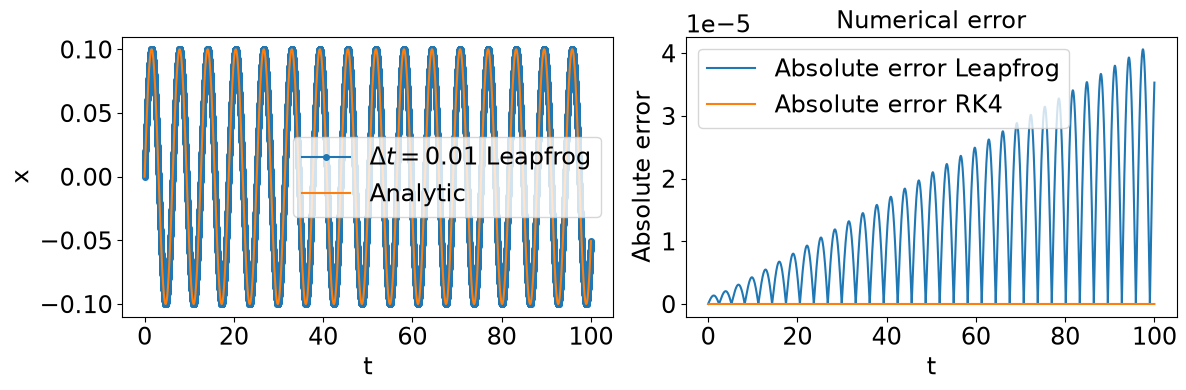

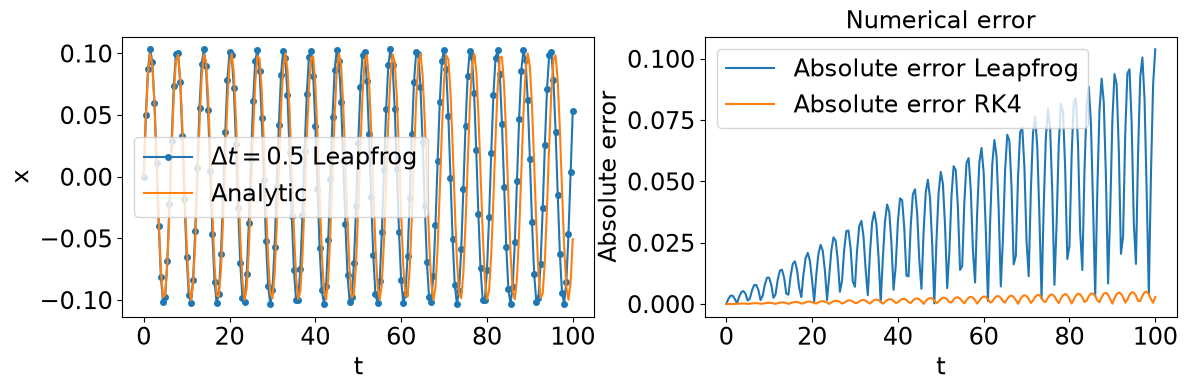

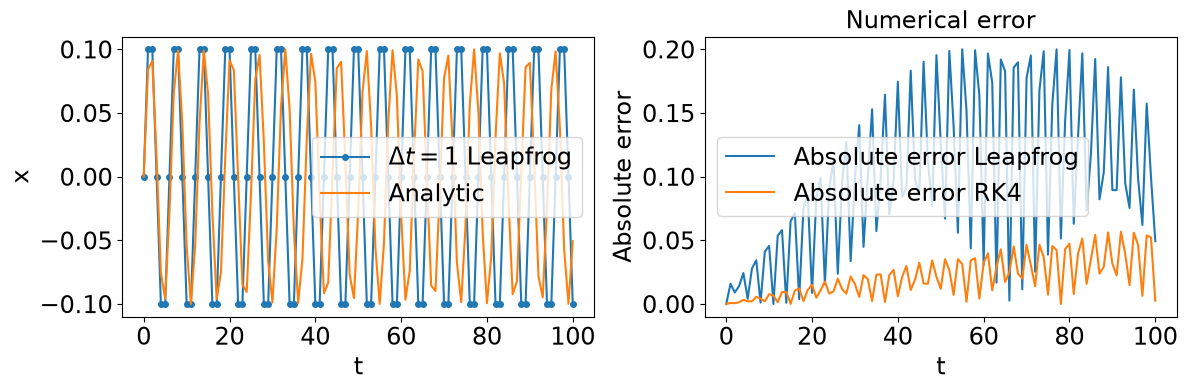

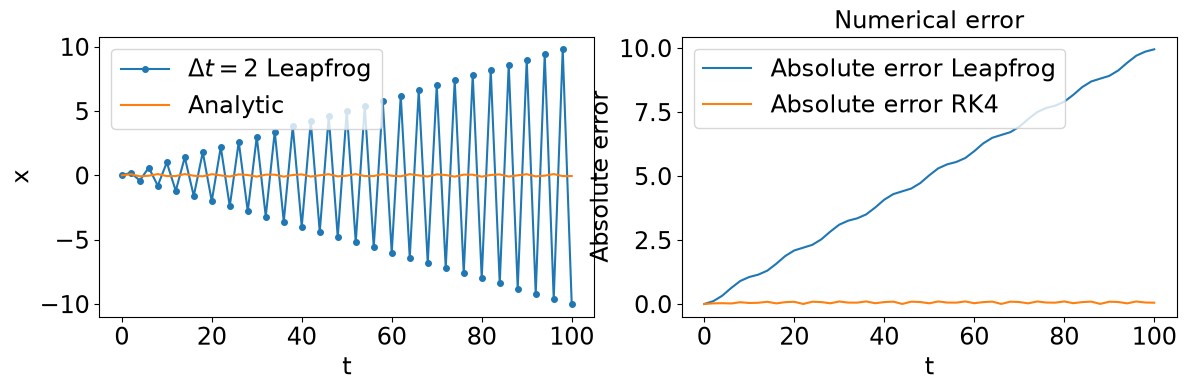

In [11]:
k, m = 1, 1
om = np.sqrt(k/m)
x_0, v_0 = 0, 0.1
start_time = 0
end_time = 100
y0 = np.array([v_0, x_0])

def spring_leap(x, k, m):
    return -k / m * x

def spring(x, y, k, m):
    v, x = y
    dv = -k / m * x
    dx = v
    return np.array([dv, dx])

def spring_analytic(t):
    return v_0 /om * np.sin(om * t) + x_0 * np.cos(om * t)

dts = [0.001, 0.01, 0.5, 1, 2]

for dt in dts:
    t, x, _ = leapfrog(spring_leap, 0, end_time, x_0, v_0, dt, (k, m))
    x_ana = spring_analytic(t)
    error = np.abs(x - x_ana)

    t_rk4, rk4 = RK4(spring, start_time, end_time, y0, dt, (k, m))
    x_rk4 = rk4[:, 1]
    x_ana = spring_analytic(t_rk4)
    error_rk4 = np.abs(x_rk4 - x_ana)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # Numerische und analytische Lösung
    ax1.plot(t, x, '-o', markersize=4,
             label=fr'$\Delta t = {dt}$ Leapfrog')
    ax1.plot(t, spring_analytic(t), label=rf'Analytic')

    ax1.set_xlabel('t')
    ax1.set_ylabel('x')
    if dt == dts[0]:
        ax1.set_title(r'Leapfrog for spring. $\omega = ' + f'${om}. ' + r'$\Delta t$ must be < ' + f' {2/om:.0f}')
    ax1.legend()

    # Absolute Abweichung
    ax2.plot(t, error, label='Absolute error Leapfrog')
    ax2.plot(t, error_rk4, label='Absolute error RK4')

    ax2.set_xlabel('t')
    ax2.set_ylabel('Absolute error')
    ax2.set_title('Numerical error')
    ax2.legend()

    fig.tight_layout()
    plt.show()


The RK4 method is a 4th order method, so it is not surprising, that its error is much smaller. However, Leapfrog is cheaper in computer resources, and when the focus is only on longtime stability and an approximate result it could be the better choice. For Leapfrog $\Delta t < \frac{2}{\omega}$ must be fullfilled, otherwise crazy things happen, as we can see.

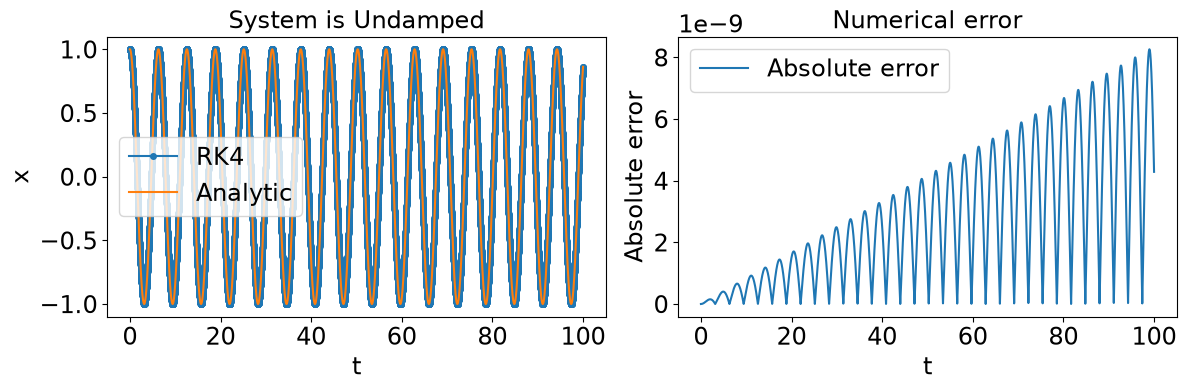

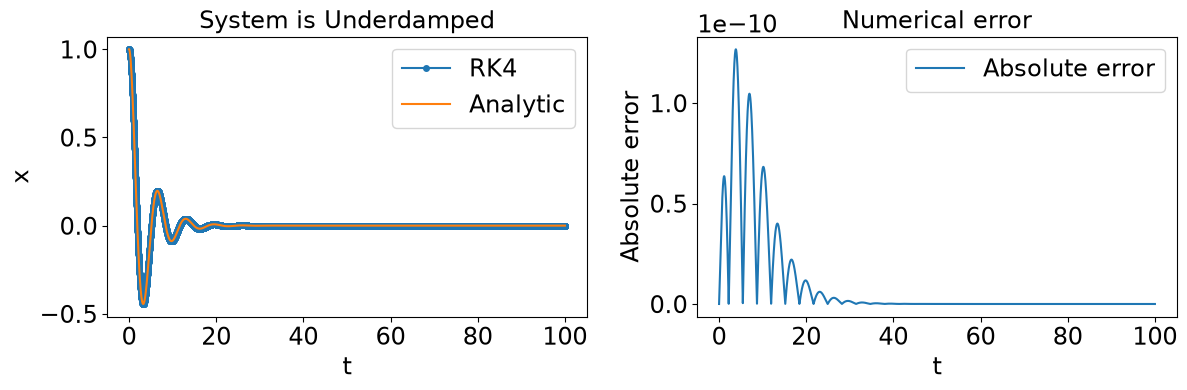

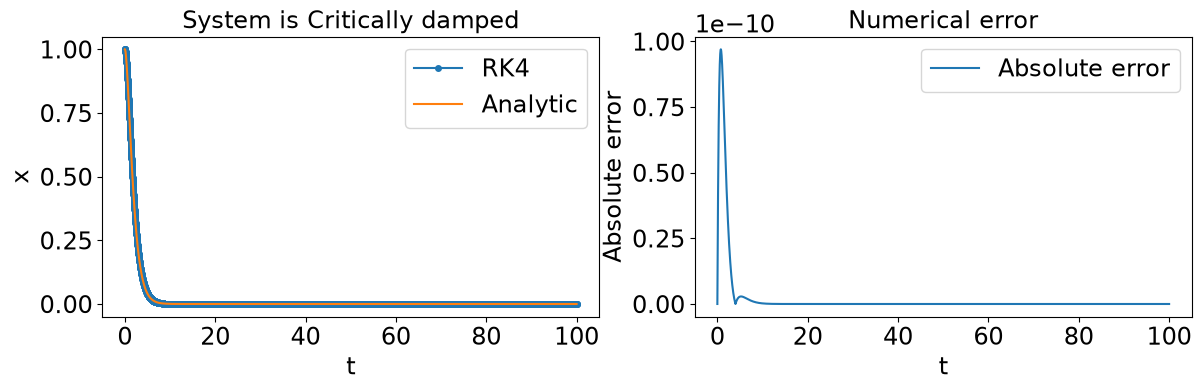

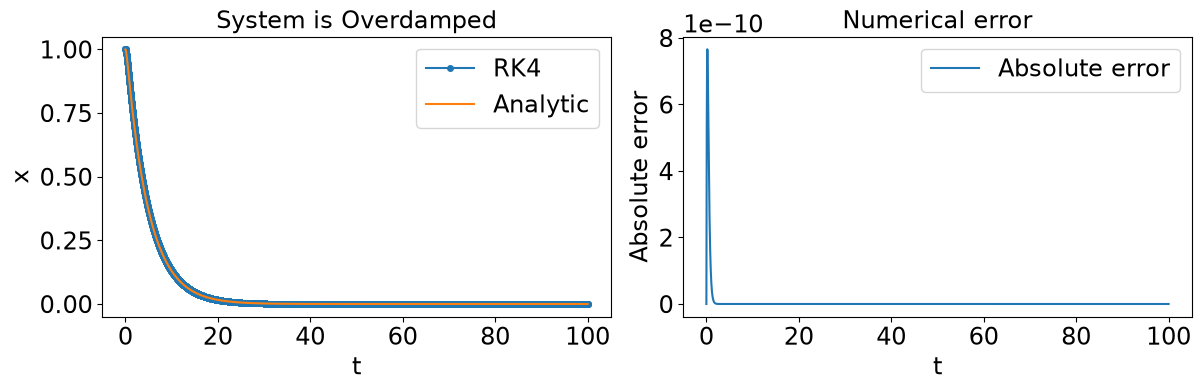

In [12]:
#C
def damped_spring_analytic(t, iK, iM, iD, x0, v0):
    # ODE: x'' + (D/m)x' + (k/m)x = 0
    alpha = iD / (2 * iM)
    discriminant = 4 * iM * iK - iD**2

    if iD == 0:  # Undamped
        omega = np.sqrt(iK / iM)
        return x0 * np.cos(omega * t) + (v0 / omega) * np.sin(omega * t), 'Undamped'

    elif discriminant > 0:  # Underdamped
        omega_d = np.sqrt(discriminant) / (2 * iM)
        return np.exp(-alpha * t) * (
            x0 * np.cos(omega_d * t)
            + (v0 + alpha * x0) / omega_d * np.sin(omega_d * t)
        ), 'Underdamped'

    elif discriminant < 0:  # Overdamped
        root = np.sqrt(-discriminant)
        r1 = (-iD + root) / (2 * iM)
        r2 = (-iD - root) / (2 * iM)
        c1 = (v0 - r2 * x0) / (r1 - r2)
        c2 = (r1 * x0 - v0) / (r1 - r2)
        return c1 * np.exp(r1 * t) + c2 * np.exp(r2 * t), 'Overdamped'

    else:  # Critically damped
        return (x0 + (v0 + alpha * x0) * t) * np.exp(-alpha * t), 'Critically damped'

K = 1
M = 1
D = 20
start_time = 0
end_time = 100
x_0, v_0 = 1, 0

def spring(t, y, k, m, d):
    v, x = y

    dv = - k / m * x - d / m * v
    dx = v

    return np.array([dv, dx])

y0 = np.array([v_0, x_0])

Ds = [0, 0.5, 2, 5]
for D in Ds:
    t, rk4 = RK4(spring, start_time, end_time, y0, 0.01, (K, M, D))
    x_rk4 = rk4[:, 1]
    x_ana, damping = damped_spring_analytic(t, K, M, D, x_0, v_0)
    error = np.abs(x_rk4 - x_ana)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # Numerische und analytische Lösung
    ax1.plot(t, x_rk4, '-o', markersize=4, label=fr'RK4')
    ax1.plot(t, x_ana, label=rf'Analytic')

    ax1.set_xlabel('t')
    ax1.set_ylabel('x')
    ax1.set_title(f'System is {damping}')
    ax1.legend()

    # Absolute Abweichung
    ax2.plot(t, error, label=f'Absolute error')

    ax2.set_xlabel('t')
    ax2.set_ylabel('Absolute error')
    ax2.set_title('Numerical error')
    ax2.legend()

    fig.tight_layout()
    plt.show()


Leapfrog cannot be used out-of-the-box for the damped oscillation, because Leapfrog solves x" = A(x) and the damped oscillator has x" = A(x, x'). However, it is possible to modify the algorithm, but then it would not be a "true" Leapfrog. One of its characteristic is energy conservation, and the damped oscillator is no conservative system, so it is not the best choice for this type of problem. A Runge-Kutta is fine, or maybe a Euler-Crome.